In [16]:
import math
import numpy as np
import random
import pandas as pd

In [28]:
# nn setup, everything from previous file

class neuron:
    def __init__(self, num_inputs, activation = "sigmoid"):
        self.weights = [random.uniform(-1,1) for _ in range(num_inputs)]
        self.bias = 0
        self.inputs = []
        self.total = 0
        self.output = 0
        self.error = 0
        self.activation, self.derivative = ACTIVATIONS[activation]

    def forward(self, inputs):
        self.inputs = inputs
        self.total = sum(w * x for w, x in zip(self.weights, inputs)) + self.bias
        self.output =  self.activation(self.total)
        return self.output

class layer:
    def __init__(self, num_neurons, num_inputs_per_neuron, activation="sigmoid"):
        self.neurons = [neuron(num_inputs_per_neuron, activation=activation) for _ in range(num_neurons)]
    def forward(self, inputs):
        return[neuron.forward(inputs) for neuron in self.neurons]

class nn:
    def __init__(self, num_inputs, hidden_layer_num, hidden_layer_size, num_outputs):
        # self.first_layer = layer(hidden_layer_size,num_inputs)
        # self.hidden_layer = layer(hidden_layer_size,hidden_layer_size)
        # self.final_layer = layer(num_outputs, hidden_layer_size)
        self.layers = []
        self.layers.append(layer(hidden_layer_size,num_inputs))
        for _ in range(hidden_layer_num-1):
            self.layers.append(layer(hidden_layer_size,hidden_layer_size))
        self.layers.append(layer(num_outputs, hidden_layer_size))
    
    def forward(self,inputs):
        x = inputs
        for l in self.layers:
            x = l.forward(x)
        return x
    
    def backward(self,targets):
        output_layer = self.layers[-1]
        for i, neuron in enumerate(output_layer.neurons):
            error = neuron.output - targets[i]
            for i, neuron in enumerate(output_layer.neurons):
                neuron.error = neuron.output - targets[i]

        for l in range(len(self.layers) - 2, -1, -1):
            current_layer = self.layers[l]
            next_layer = self.layers[l+1]
            for i, neuron in enumerate(current_layer.neurons):
                error = sum(next_neuron.weights[i] * next_neuron.error for next_neuron in next_layer.neurons)
                neuron.error  = error * neuron.derivative(neuron.output)
    def update_weights(self, learning_rate=0.5):
        for l in self.layers:
            for neuron in l.neurons:
                for j in range(len(neuron.weights)):
                    neuron.weights[j] -= learning_rate * neuron.error * neuron.inputs[j]
                neuron.bias -= learning_rate * neuron.error

# activation functions
def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-np.clip(x, -500, 500))) 

def tanh(x):
    return np.tanh(x)

def ReLU(x):
    return np.maximum(0, x)

def lRelu(x, alpha=0.1):
    return np.maximum(x * alpha, x)

def pRelu(x, a=0.25):
    return np.maximum(x * a, x)


# derivatives
def sigmoid_derivative(output):
    return output * (1.0 - output)

def tanh_derivative(output):
    return 1.0 - (output ** 2)

def Relu_derivative(output):
    return np.where(output > 0, 1.0, 0.0)

def lRelu_derivative(output, alpha=0.1):
    return np.where(output > 0, 1.0, alpha)

def pRelu_derivative(output, a=0.25):
    return np.where(output > 0, 1.0, a)

ACTIVATIONS = {
    'sigmoid': (sigmoid, sigmoid_derivative),
    'relu': (ReLU, Relu_derivative),
    'tanh': (tanh, tanh_derivative),
    'lRelu': (lRelu, lRelu_derivative)
}


In [18]:
# csv file structure:
# 1 line top padding
# then each img is one line
# 28 x 28 grid, going all of top row, then all of second row ...
# 60,000 in train csv, 10,000 in test csv

def dataloader(filepath):
    df = pd.read_csv(filepath)
    labels = df.iloc[1:,0].values
    values = df.iloc[1:,1:].values

    # rgb values normalised to mag 1
    values = values/255

    return values, labels


# kernels for convolution
vertical_edge_kernel = np.array([
    [-1,0,1],
    [-1,0,1],
    [-1,0,1]
])
horizontal_edge_kernel = np.array([
    [1,1,1],
    [0,0,0],
    [-1,-1,-1]
])
sharpening_kernel = np.array([
    [0,-1,0],
    [-1,5,-1],
    [0,-1,0]
])

In [19]:
def conv_2d_single(image_flat, kernel, padding=0):

    # reshape flat 784 vector into 2D grid
    image_2d = image_flat.reshape(28, 28)
    
    # apply padding if requested
    if padding > 0:
        image_2d = np.pad(image_2d, pad_width=padding, mode='constant', constant_values=0)
        
    kernel_h, kernel_w = kernel.shape
    img_h, img_w = image_2d.shape
    
    # calculate output feature map dimensions
    out_h = img_h - kernel_h + 1
    out_w = img_w - kernel_w + 1
    
    output = np.zeros((out_h, out_w))
    
    # perform sliding window convolution
    for r in range(out_h):
        for c in range(out_w):
            region = image_2d[r:r+kernel_h, c:c+kernel_w]
            output[r, c] = np.sum(region * kernel)
            
    return output

In [20]:
def one_hot(label, num_classes=10):
    target = [0.0] * num_classes
    target[int(label)] = 1.0
    return target

In [ ]:
epochs = 10
lr = 0.05
# training_per_epoch = 1000

# x = data, y = label
train_x, train_y = dataloader("data/mnist/mnist_train.csv")
test_x, test_y = dataloader("data/mnist/mnist_test.csv")

model = nn(num_inputs=2352, hidden_layer_num=1, hidden_layer_size= 64, num_outputs= 10)
for l in model.layers[:-1]:
    for n in l.neurons:
        n.activation, n.derivative = ACTIVATIONS['lRelu']
for n in model.layers[-1].neurons:
    n.activation, n.derivative = ACTIVATIONS['sigmoid']

for epoch in range(epochs):
    total_loss = 0
    correct = 0
    for i, (image, label) in enumerate(zip(train_x[:1000], train_y[:1000])):
        # convalution of grid
        # then regular nn from last time
        # note use lrelu for activation
        feature_map1 = conv_2d_single(image, vertical_edge_kernel, padding=1)
        feature_map2 = conv_2d_single(image, horizontal_edge_kernel, padding=1)
        feature_map3 = conv_2d_single(image, sharpening_kernel, padding= 1)

        activ1 = lRelu(feature_map1)
        activ2 = lRelu(feature_map2)
        activ3 = lRelu(feature_map3)

        nn_input = np.hstack([activ1.flatten(),activ2.flatten(),activ3.flatten()])
        nn_input = nn_input/ np.max(nn_input)

        target = one_hot(label)
        predictions = model.forward(nn_input)

        loss = sum((p - t) ** 2 for p, t in zip(predictions, target))
        total_loss += loss
        
        predicted_digit = predictions.index(max(predictions))
        if predicted_digit == int(label):
            correct += 1
        model.backward(target)
        model.update_weights(learning_rate=lr)
        if (i + 1) % 200 == 0:
            print(f"Epoch {epoch+1} | Image {i+1}/1000 | Recent Acc: {correct/(i+1)*100:.1f}%")
            
    print(f"=== Epoch {epoch+1} Summary: Avg Loss = {total_loss/1000:.4f}, Accuracy = {correct/1000*100:.2f}% ===")


Epoch 1 | Image 200/1000 | Recent Acc: 43.5%
Epoch 1 | Image 400/1000 | Recent Acc: 55.8%
Epoch 1 | Image 600/1000 | Recent Acc: 57.3%
Epoch 1 | Image 800/1000 | Recent Acc: 60.4%
Epoch 1 | Image 1000/1000 | Recent Acc: 63.1%
=== Epoch 1 Summary: Avg Loss = 0.7541, Accuracy = 63.10% ===
Epoch 2 | Image 200/1000 | Recent Acc: 85.0%
Epoch 2 | Image 400/1000 | Recent Acc: 87.5%
Epoch 2 | Image 600/1000 | Recent Acc: 86.3%
Epoch 2 | Image 800/1000 | Recent Acc: 86.8%
Epoch 2 | Image 1000/1000 | Recent Acc: 87.6%
=== Epoch 2 Summary: Avg Loss = 0.2409, Accuracy = 87.60% ===
Epoch 3 | Image 200/1000 | Recent Acc: 93.5%
Epoch 3 | Image 400/1000 | Recent Acc: 94.0%
Epoch 3 | Image 600/1000 | Recent Acc: 94.0%
Epoch 3 | Image 800/1000 | Recent Acc: 94.4%
Epoch 3 | Image 1000/1000 | Recent Acc: 94.3%
=== Epoch 3 Summary: Avg Loss = 0.1194, Accuracy = 94.30% ===
Epoch 4 | Image 200/1000 | Recent Acc: 96.0%
Epoch 4 | Image 400/1000 | Recent Acc: 97.2%
Epoch 4 | Image 600/1000 | Recent Acc: 97.7%
E

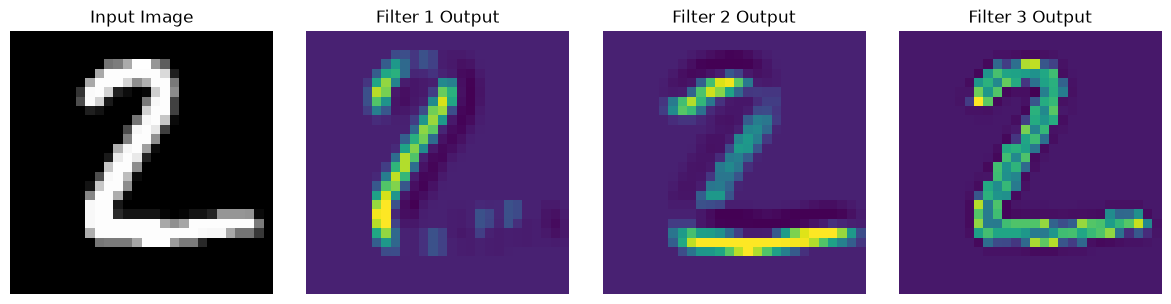

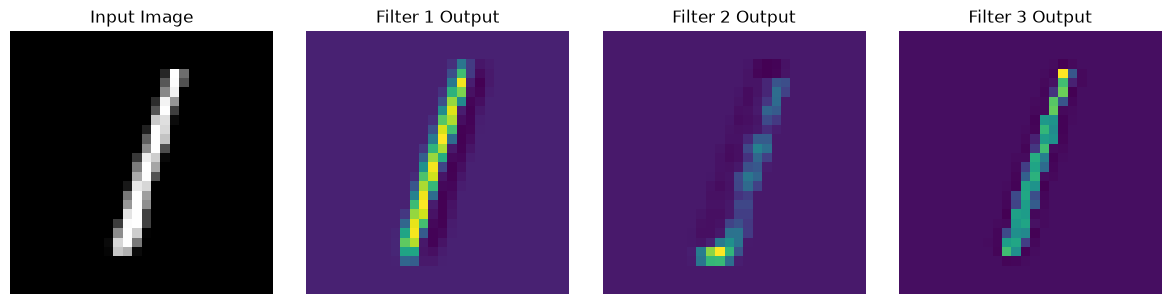

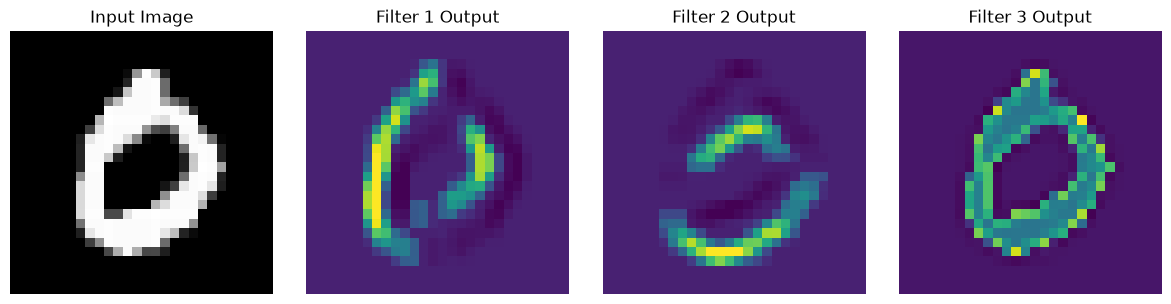

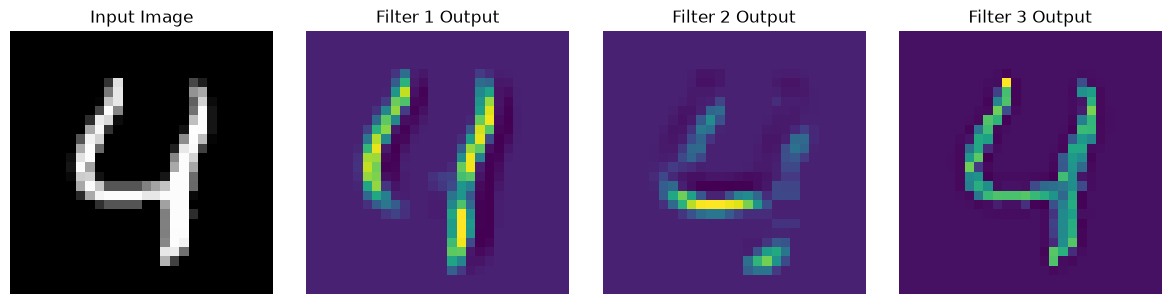

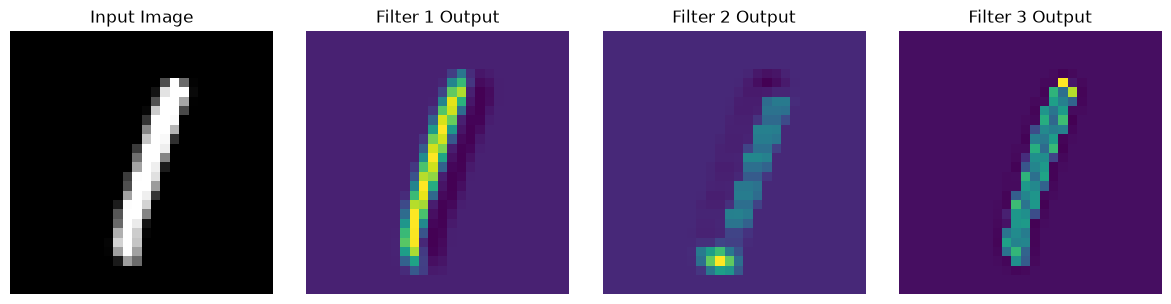

In [35]:
import matplotlib.pyplot as plt
kernels = [vertical_edge_kernel, horizontal_edge_kernel, sharpening_kernel]

def visualize_conv_features(sample_image, kernels):
    feat_maps = [conv_2d_single(sample_image, k, padding=1) for k in kernels]
    acts = [lRelu(fm) for fm in feat_maps]
    
    num_filters = len(kernels)
    fig, axes = plt.subplots(1, num_filters + 1, figsize=(3 * (num_filters + 1), 3))
    
    axes[0].imshow(sample_image.reshape(28, 28), cmap='gray')
    axes[0].set_title("Input Image")
    axes[0].axis('off')
    
    for idx, act in enumerate(acts):
        axes[idx + 1].imshow(act, cmap='viridis')
        axes[idx + 1].set_title(f"Filter {idx+1} Output")
        axes[idx + 1].axis('off')
        
    plt.tight_layout()
    plt.show()

for i in range(5):
    visualize_conv_features(test_x[i], kernels)

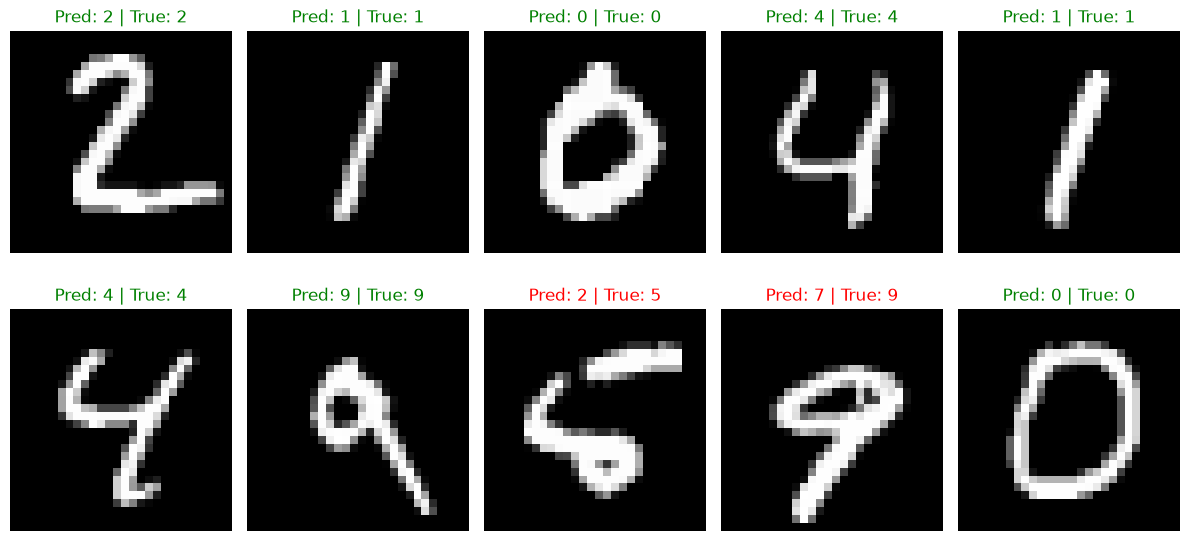

In [38]:
def plot_prediction_samples(model, kernels, test_x, test_y, num_samples=10):
    fig, axes = plt.subplots(2, 5, figsize=(12, 6))
    axes = axes.flatten()
    
    for i in range(num_samples):
        image, true_label = test_x[i], int(test_y[i])
        
        # Forward pass through Conv -> Relu -> Dense
        feat_maps = [conv_2d_single(image, k, padding=1) for k in kernels]
        acts = [lRelu(fm) for fm in feat_maps]
        conv_flat = np.hstack([a.flatten() for a in acts])
        
        max_val = np.max(np.abs(conv_flat))
        if max_val > 0: conv_flat = conv_flat / max_val
        
        preds = model.forward(conv_flat.tolist())
        pred_label = preds.index(max(preds))
        
        # Plot image
        axes[i].imshow(image.reshape(28, 28), cmap='gray')
        
        # Green if correct, Red if misclassified
        color = 'green' if pred_label == true_label else 'red'
        axes[i].set_title(f"Pred: {pred_label} | True: {true_label}", color=color)
        axes[i].axis('off')
        
    plt.tight_layout()
    plt.show()

plot_prediction_samples(model, kernels, test_x, test_y)